<a href="https://colab.research.google.com/github/Bhuvibagga/VDUI-UNIT3-PES2UG24CS117/blob/ppt1/unit3_ppt1_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in decimal MB
frame_mb = 1920 * 1080 * 3 / 1e6

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB (1 TB = 1024**4 bytes)
fleet_tb = (1920 * 1080 * 3 * frames_per_day * 400) / (1024**4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 24 * 60 * 60 * 400) / (1024**4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_  Spatial evidence: Fine details such as a person's face, clothing features, or a small object in their hand may become indistinguishable at 640 × 360 resolution. Temporal evidence: At 10 fps, a brief action occurring between sampled frames—such as a quick hand movement or an object being dropped—could be missed or its sequence could become ambiguous.


## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

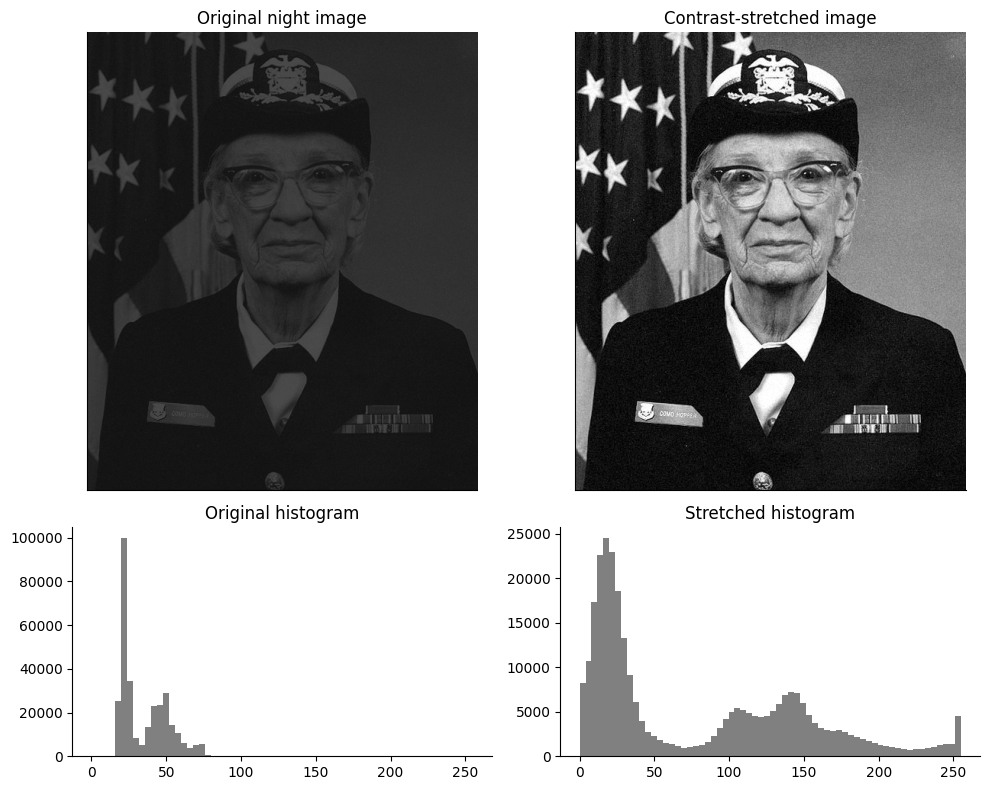

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) * 255 / (hi - lo), 0, 255)

lo_after, hi_after = np.percentile(stretched, [1, 99])
c_after = michelson(hi_after, lo_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original night image")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched image")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 0].set_title("Original histogram")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 1].set_title("Stretched histogram")
for ax in axes.flat:
    if ax in axes[0]:
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_  The original histogram is narrow and concentrated at the low-intensity end, indicating a low-contrast, murky image. Contrast stretching spreads the existing intensity values across a wider range, making differences between pixels easier to see. It does not add new scene details; it only remaps the values already present, and clipping values outside the 1st–99th percentile range can discard some intensity distinctions. A histogram records how many pixels have each intensity but not where those pixels occur, so different images can have the same histogram while depicting completely different scenes.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (speed < 3 px/s) intervals:
  68.70 s – 68.70 s
  68.77 s – 68.77 s
  68.87 s – 70.53 s
  70.60 s – 70.83 s
  70.90 s – 71.13 s
  71.20 s – 71.63 s
  71.70 s – 72.03 s
  72.10 s – 72.13 s
  72.23 s – 72.73 s
  72.80 s – 73.23 s
  73.30 s – 73.73 s
  73.80 s – 73.90 s
  73.97 s – 74.03 s
  74.10 s – 74.23 s
  74.30 s – 74.67 s
  74.73 s – 75.37 s
  75.43 s – 75.47 s
  75.53 s – 75.57 s
  75.63 s – 75.67 s
  75.73 s – 75.73 s
  75.80 s – 75.90 s
  75.97 s – 76.53 s
  76.63 s – 76.93 s
  77.00 s – 78.10 s
Running (speed > 25 px/s) intervals:
  78.60 s – 86.00 s
Audio threshold event: frame 2250, t=75.00 s
Lighting jump event: frame 3000, t=100.00 s


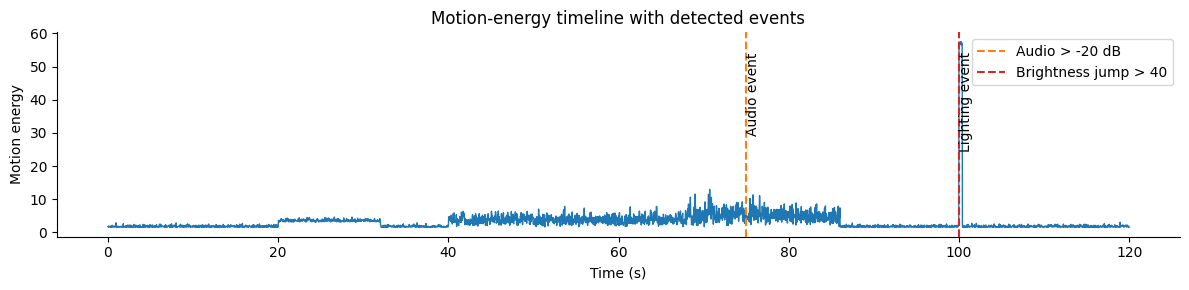

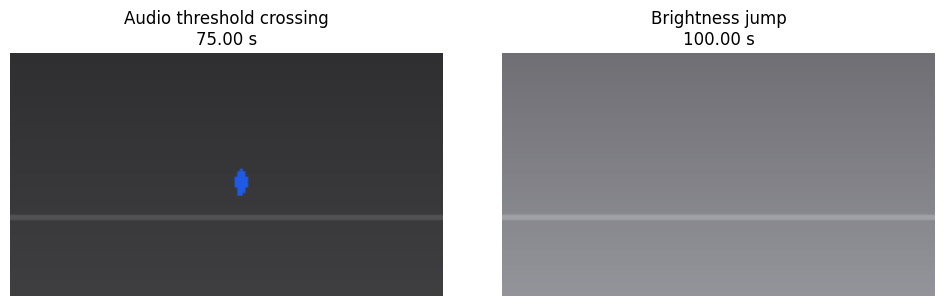

In [4]:
# TODO 1: person speed (px/s), using a one-second displacement window
time_col = next((c for c in ["time_s", "time", "timestamp", "seconds"] if c in cctv.columns), None)
if time_col is None:
    # The log is sampled at FPS, so create a time axis from its frame order.
    times = np.arange(len(cctv)) / FPS
else:
    times = cctv[time_col].to_numpy(dtype=float)

px = cctv["person_x"].to_numpy(dtype=float)
py = cctv["person_y"].to_numpy(dtype=float)
dx = pd.Series(px).diff(FPS).to_numpy()
dy = pd.Series(py).diff(FPS).to_numpy()
speed = np.hypot(dx, dy)  # displacement over 1 second = px/s
speed[~(np.isfinite(px) & np.isfinite(py))] = np.nan

# TODO 2: standing / running time ranges (print the first and last time of each)
def print_ranges(mask, label):
    mask = np.asarray(mask, dtype=bool)
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        print(f"{label}: no intervals detected")
        return
    groups = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
    print(f"{label} intervals:")
    for g in groups:
        print(f"  {times[g[0]]:.2f} s – {times[g[-1]]:.2f} s")

print_ranges(np.isfinite(speed) & (speed < 3), "Standing (speed < 3 px/s)")
print_ranges(np.isfinite(speed) & (speed > 25), "Running (speed > 25 px/s)")

# TODO 3: event frame indices
audio_hits = np.flatnonzero(cctv["audio_level_db"].to_numpy() > -20)
audio_event_idx = int(audio_hits[0]) if len(audio_hits) else None
brightness_jump = cctv["mean_brightness"].diff().to_numpy()
lighting_hits = np.flatnonzero(brightness_jump > 40)
lighting_event_idx = int(lighting_hits[0]) if len(lighting_hits) else None

print("Audio threshold event:", None if audio_event_idx is None else
      f"frame {audio_event_idx}, t={times[audio_event_idx]:.2f} s")
print("Lighting jump event:", None if lighting_event_idx is None else
      f"frame {lighting_event_idx}, t={times[lighting_event_idx]:.2f} s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(times, cctv["motion_energy"], linewidth=1)
ax.set(xlabel="Time (s)", ylabel="Motion energy", title="Motion-energy timeline with detected events")
if audio_event_idx is not None:
    ax.axvline(times[audio_event_idx], color="tab:orange", linestyle="--", label="Audio > -20 dB")
    ax.text(times[audio_event_idx], ax.get_ylim()[1] * 0.9, "Audio event", rotation=90, va="top")
if lighting_event_idx is not None:
    ax.axvline(times[lighting_event_idx], color="tab:red", linestyle="--", label="Brightness jump > 40")
    ax.text(times[lighting_event_idx], ax.get_ylim()[1] * 0.9, "Lighting event", rotation=90, va="top")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
event_frames = [("Audio threshold crossing", audio_event_idx),
                ("Brightness jump", lighting_event_idx)]
valid_events = [(label, idx) for label, idx in event_frames if idx is not None]
if valid_events:
    fig, axes = plt.subplots(1, len(valid_events), figsize=(5 * len(valid_events), 3))
    if len(valid_events) == 1:
        axes = [axes]
    for ax, (label, idx) in zip(axes, valid_events):
        ax.imshow(render_frame(cctv.iloc[idx]))
        ax.set_title(f"{label}\n{times[idx]:.2f} s")
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No audio or lighting event frames found to display.")

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_  Uniform keyframes every 20 seconds could miss brief events such as the sudden audio impact near 75 s or a one-frame brightness jump, especially if they occur between selected frames. It could also miss a short burst of running or another sparse movement. The approach used here is content-based (event-driven) keyframe selection, choosing representative frames based on detected changes rather than fixed time intervals.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

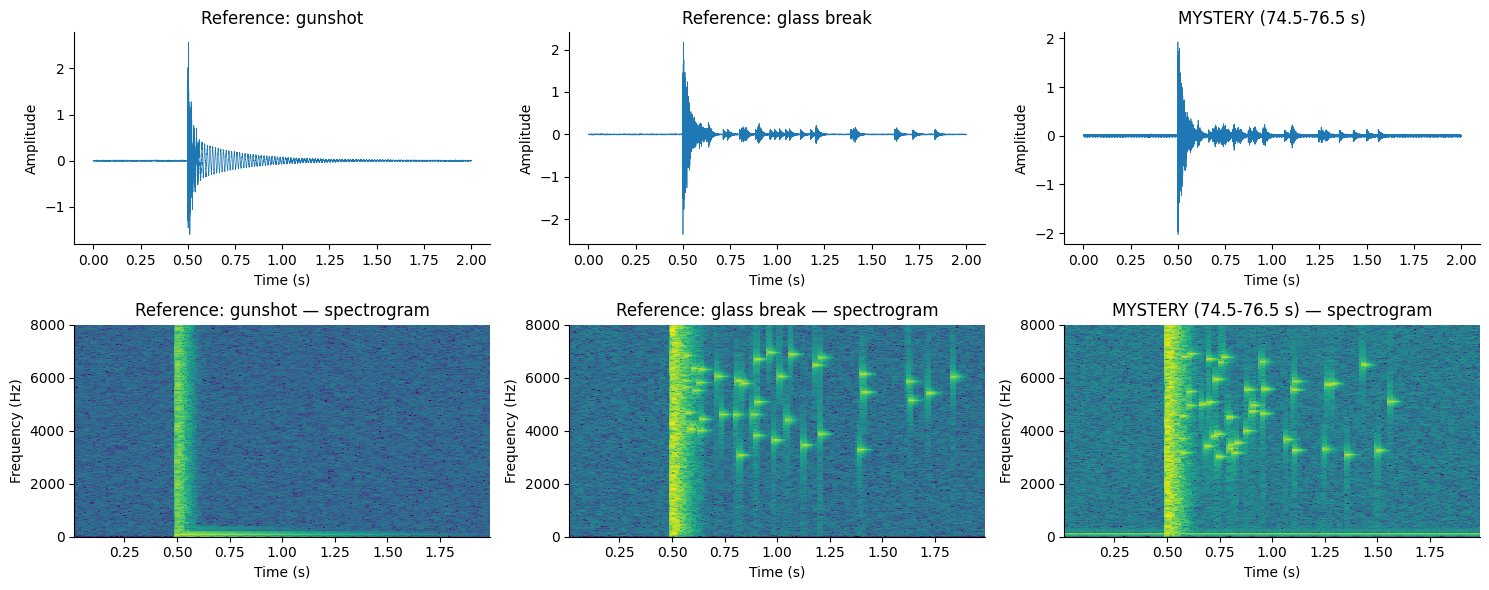

{'Reference: gunshot': np.float64(0.0030352610136762824), 'Reference: glass break': np.float64(0.9891874044148661), 'MYSTERY (74.5-76.5 s)': np.float64(0.8734552491106999)}
Verdict: the mystery sound is most consistent with BREAKING GLASS.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for j, (label, x) in enumerate(clips.items()):
    tx = np.arange(len(x)) / FS
    axes[0, j].plot(tx, x, linewidth=0.5)
    axes[0, j].set_title(label)
    axes[0, j].set_xlabel("Time (s)")
    axes[0, j].set_ylabel("Amplitude")
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    Sdb = 10 * np.log10(Sxx + 1e-12)
    axes[1, j].pcolormesh(tt, f, Sdb, shading="auto")
    axes[1, j].set_ylim(0, 8000)
    axes[1, j].set_xlabel("Time (s)")
    axes[1, j].set_ylabel("Frequency (Hz)")
    axes[1, j].set_title(f"{label} — spectrogram")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for label, x in clips.items():
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    time_mask = (tt >= 0.7) & (tt <= 1.7)  # 0.2–1.2 s after the 0.5 s impact
    freq_mask = f > 3000
    energy_window = Sxx[:, time_mask]
    total_energy = energy_window.sum()
    hf_energy = energy_window[freq_mask, :].sum()
    hf_fraction[label] = hf_energy / total_energy if total_energy else 0.0

print(hf_fraction)
# TODO 4: verdict
mystery_hf = hf_fraction["MYSTERY (74.5-76.5 s)"]
glass_hf = hf_fraction["Reference: glass break"]
gun_hf = hf_fraction["Reference: gunshot"]
verdict = "BREAKING GLASS" if abs(mystery_hf - glass_hf) < abs(mystery_hf - gun_hf) else "GUNSHOT"
print(f"Verdict: the mystery sound is most consistent with {verdict}.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No. The waveforms mainly show amplitude changes over time, and both sounds can have a sharp, loud impact that looks similar. A spectrogram adds time, frequency, and magnitude/energy. The mystery clip is most consistent with breaking glass: the lingering, scattered high-frequency specks after the initial vertical impact stripe indicate small glass fragments tinkling, unlike a gunshot's brief broadband crack and low-frequency decay.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

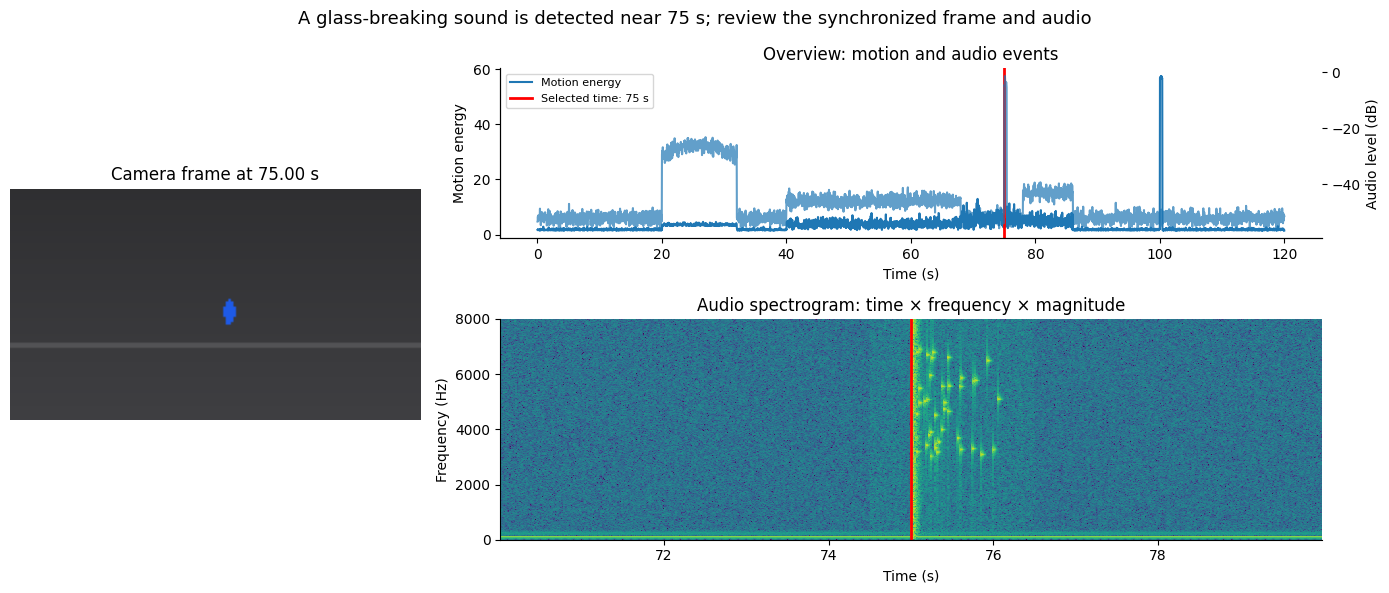

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1: rendered video frame at t = 75 s (left)
time_col = next((c for c in ["time_s", "time", "timestamp", "seconds"] if c in cctv.columns), None)
times = cctv[time_col].to_numpy(dtype=float) if time_col else np.arange(len(cctv)) / FPS
frame_idx = int(np.argmin(np.abs(times - t_sel)))
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title(f"Camera frame at {times[frame_idx]:.2f} s")
ax_frame.axis("off")

# TODO 2: full motion + audio timeline with red marker at 75 s (top right)
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(times, cctv["motion_energy"], label="Motion energy")
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion energy")
ax_timeline.set_title("Overview: motion and audio events")
ax_audio = ax_timeline.twinx()
ax_audio.plot(times, cctv["audio_level_db"], alpha=0.7, label="Audio level (dB)")
ax_audio.set_ylabel("Audio level (dB)")
ax_timeline.axvline(t_sel, color="red", linewidth=2, label="Selected time: 75 s")
ax_timeline.legend(loc="upper left", fontsize=8)

# TODO 3: spectrogram of x_audio (70–80 s) with same marker
ax_spec = fig.add_subplot(gs[1, 1])
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
Sdb = 10 * np.log10(Sxx + 1e-12)
ax_spec.pcolormesh(tt + 70, f, Sdb, shading="auto")
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio spectrogram: time × frequency × magnitude")
ax_spec.axvline(t_sel, color="red", linewidth=2)

# TODO 4: conclusion-style figure title
fig.suptitle("A glass-breaking sound is detected near 75 s; review the synchronized frame and audio", fontsize=13)
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_If the audio were offset by +2 s, the impact would appear to occur two seconds later than the corresponding video event. The briefing could incorrectly associate the sound with a different person, movement, or lighting change, leading to a false conclusion about what happened. The synchronized audio spectrogram and timeline panel, with the shared 75 s marker, would make the mismatch visible because the audio event would no longer line up with the video timeline.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ The camera and audio review indicates a sharp impact consistent with breaking glass near 75 seconds, supported by the lingering high-frequency components in the spectrogram. I would put the synchronized multimodal view first because it links the representative video frame, the event timeline, and the sound's time–frequency–magnitude pattern at a common timestamp. This follows the lecture's structure → pattern → change → event → meaning approach and helps the reviewer move quickly from overview to evidence. Storing all 400 cameras at 1080p and 30 fps would require approximately 5,866 TiB per day of uncompressed video, while 640 × 360 at 10 fps would require about 217 TiB per day. I recommend using lower resolution and frame rate only for routine monitoring, while preserving full-quality clips around detected events so brief actions and identifying spatial details are not lost.